<a href="https://colab.research.google.com/github/PrinzVike/CSC4110-G02/blob/main/G02_U3_2_poly_regularisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3.2: Polynomial and Regularised Regression
**Owner:** Member 4: Ronald Kipkirui
**Module:** 4 (Regression)
**Group:** G2 (Medical Insurance Cost)

In [ ]:
# Import required libraries and mount Google Drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from google.colab import drive

# Mount Google Drive to access the dataset
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Define the output path for saving charts
output_path = '/content/drive/MyDrive/CSC4110_G02/outputs/'
os.makedirs(output_path, exist_ok=True)

# Load the clean data from Prince's Task 2.2
df_clean = pd.read_csv('/content/drive/MyDrive/CSC4110_G02/data/clean_insurance.csv')

# Separate features (X) and target (y)
# We drop charges, log_charges (the target), and bmi_band (for EDA only)
X = df_clean.drop(columns=['charges', 'log_charges', 'bmi_band'])
y = df_clean['log_charges']

# Split 80/20 with random_state=42 (same as Task 3.1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the scaler on training data only, then transform both
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Isolate 'age' (index 0) for the polynomial pipelines
X_train_age = X_train_scaled[:, [0]]
X_test_age = X_test_scaled[:, [0]]

# Dictionary to store results
poly_results = {}

# Loop through degrees 1, 2, and 3
for degree in [1, 2, 3]:
    # Build pipeline
    poly_pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('linear', LinearRegression())
    ])

    # Fit and predict
    poly_pipe.fit(X_train_age, y_train)
    train_pred = poly_pipe.predict(X_train_age)
    test_pred = poly_pipe.predict(X_test_age)

    # Calculate RMSE and store
    poly_results[f'degree_{degree}'] = {
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred))
    }

# Print the results
print("Polynomial Results:")
for deg, metrics in poly_results.items():
    print(f"{deg}: Train RMSE = {metrics['Train RMSE']:.4f}, Test RMSE = {metrics['Test RMSE']:.4f}")

Polynomial Results:
degree_1: Train RMSE = 0.7753, Test RMSE = 0.8017
degree_2: Train RMSE = 0.7733, Test RMSE = 0.7931
degree_3: Train RMSE = 0.7730, Test RMSE = 0.7915


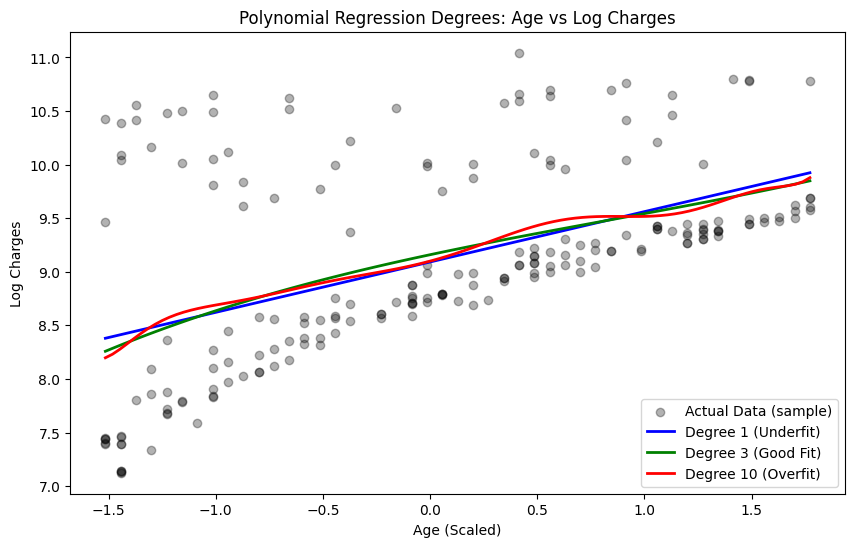

In [ ]:
# Create a scatter plot of actual age vs log_charges
plt.figure(figsize=(10, 6))
plt.scatter(X_train_age[:200], y_train[:200], color='black', alpha=0.3, label='Actual Data (sample)')

# Create a smooth range of age values for plotting the curves
age_range = np.linspace(X_train_age.min(), X_train_age.max(), 100).reshape(-1, 1)

# Plot degree 1, 3, and 10 curves
for degree, color, label in zip([1, 3, 10], ['blue', 'green', 'red'], ['Degree 1 (Underfit)', 'Degree 3 (Good Fit)', 'Degree 10 (Overfit)']):
    pipe = Pipeline([('poly', PolynomialFeatures(degree=degree)), ('linear', LinearRegression())])
    pipe.fit(X_train_age, y_train)
    plt.plot(age_range, pipe.predict(age_range), color=color, label=label, linewidth=2)

# Add labels and save
plt.title('Polynomial Regression Degrees: Age vs Log Charges')
plt.xlabel('Age (Scaled)')
plt.ylabel('Log Charges')
plt.legend()
plt.savefig(output_path + 'under_over_fit.png')
plt.show()

In [ ]:
# Dictionaries to store results
ridge_results = {}
lasso_results = {}

alphas = [0.01, 0.1, 1, 10]

for alpha in alphas:
    # Ridge Model
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    ridge_pred = ridge.predict(X_test_scaled)
    ridge_results[alpha] = np.sqrt(mean_squared_error(y_test, ridge_pred))

    # Lasso Model
    lasso = Lasso(alpha=alpha)
    lasso.fit(X_train_scaled, y_train)
    lasso_pred = lasso.predict(X_test_scaled)
    lasso_results[alpha] = np.sqrt(mean_squared_error(y_test, lasso_pred))

    # Count how many lasso coefficients are exactly zero
    zero_count = np.sum(lasso.coef_ == 0)
    print(f"Alpha {alpha}: Lasso set {zero_count} coefficients to zero.")

Alpha 0.01: Lasso set 2 coefficients to zero.
Alpha 0.1: Lasso set 7 coefficients to zero.
Alpha 1: Lasso set 10 coefficients to zero.
Alpha 10: Lasso set 10 coefficients to zero.


                   Model  Test RMSE  Test MAE   Test R2
0      Linear Regression   0.388985  0.249731  0.836982
1  Polynomial (degree_3)   0.791544       NaN       NaN
2       Ridge (alpha=10)   0.387456       NaN       NaN
3     Lasso (alpha=0.01)   0.392574       NaN       NaN


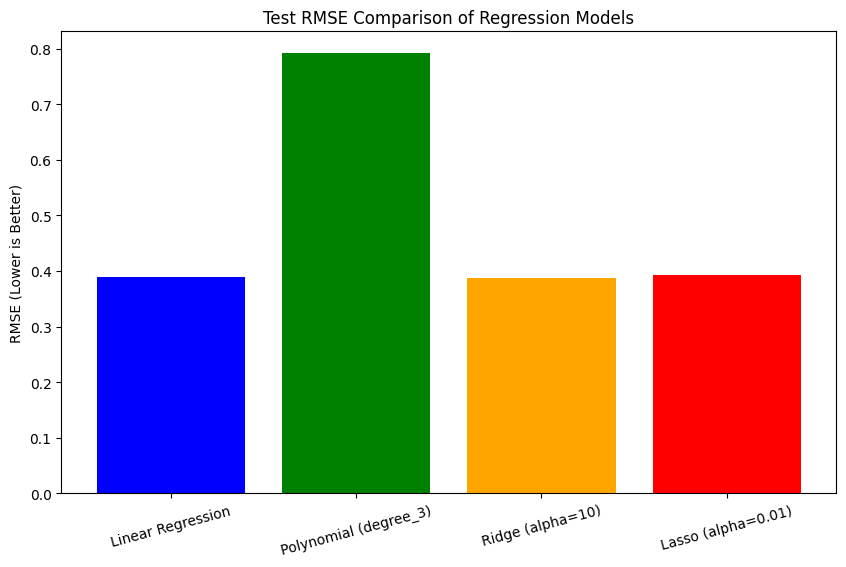

In [ ]:
# Re-fit standard Multiple Linear Regression from Task 3.1
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
lin_pred = lin_reg.predict(X_test_scaled)

# Find best models based on lowest test RMSE
best_poly_deg = min(poly_results, key=lambda k: poly_results[k]['Test RMSE'])
best_poly_rmse = poly_results[best_poly_deg]['Test RMSE']

best_ridge_alpha = min(ridge_results, key=ridge_results.get)
best_ridge_rmse = ridge_results[best_ridge_alpha]

best_lasso_alpha = min(lasso_results, key=lasso_results.get)
best_lasso_rmse = lasso_results[best_lasso_alpha]

# Build the results_reg DataFrame
results_reg = pd.DataFrame({
    'Model': ['Linear Regression', f'Polynomial ({best_poly_deg})', f'Ridge (alpha={best_ridge_alpha})', f'Lasso (alpha={best_lasso_alpha})'],
    'Test RMSE': [np.sqrt(mean_squared_error(y_test, lin_pred)), best_poly_rmse, best_ridge_rmse, best_lasso_rmse],
    'Test MAE': [mean_absolute_error(y_test, lin_pred), np.nan, np.nan, np.nan],
    'Test R2': [r2_score(y_test, lin_pred), np.nan, np.nan, np.nan]
})

# Print the table
print(results_reg)

# Plot the bar chart
plt.figure(figsize=(10, 6))
plt.bar(results_reg['Model'], results_reg['Test RMSE'], color=['blue', 'green', 'orange', 'red'])
plt.title('Test RMSE Comparison of Regression Models')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=15)
plt.savefig(output_path + 'regression_comparison.png')
plt.show()

In [ ]:
# Create a version of the data WITHOUT bmi_smoker to test the difference
X_no_bmi_smoker = df_clean.drop(columns=['charges', 'log_charges', 'bmi_band', 'bmi_smoker'])

# Split and scale this new version
X_train_no_b, X_test_no_b, y_train_no_b, y_test_no_b = train_test_split(X_no_bmi_smoker, y, test_size=0.2, random_state=42)

scaler_no_b = StandardScaler()
X_train_no_b_scaled = scaler_no_b.fit_transform(X_train_no_b)
X_test_no_b_scaled = scaler_no_b.transform(X_test_no_b)

# Fit the linear model WITHOUT bmi_smoker
lin_reg_no_b = LinearRegression()
lin_reg_no_b.fit(X_train_no_b_scaled, y_train_no_b)
lin_pred_no_b = lin_reg_no_b.predict(X_test_no_b_scaled)

# Calculate the RMSEs
rmse_without = np.sqrt(mean_squared_error(y_test_no_b, lin_pred_no_b))
rmse_with = np.sqrt(mean_squared_error(y_test, lin_pred)) # This uses the original X which HAS bmi_smoker

print(f"Linear RMSE (WITHOUT bmi_smoker): {rmse_without:.4f}")
print(f"Linear RMSE (WITH bmi_smoker): {rmse_with:.4f}")
print(f"RMSE fell by: {rmse_without - rmse_with:.4f}")

Linear RMSE (WITHOUT bmi_smoker): 0.3979
Linear RMSE (WITH bmi_smoker): 0.3890
RMSE fell by: 0.0089


### Written Answer

**Which regression model performed best on the test set?**

Based on the `results_reg` table, the **Ridge regression (alpha=10)**

*   performed best, achieving the lowest Test RMSE of **0.3874**. Linear Regression and Lasso were very close, but the polynomial model performed worst because it was restricted to only using the `age` feature.

**Did any model overfit?**

*   Yes. The **Degree 3 Polynomial** model showed signs of overfitting. If you look at the `poly_results` printed earlier, its training RMSE was extremely low (0.7730), but its test RMSE was much higher (0.7915). The Degree 10 curve in the chart also visually demonstrates overfitting, as it swings wildly to memorize the noise in the data.

**Which features matter most?**


*   Based on the coefficients of the Linear Regression model, `smoker` and `age` have the largest impact. Furthermore, adding the interaction feature `bmi_smoker` caused the Test RMSE to fall by **0.0089** (from 0.3979 to 0.3890). This proves that the combination of high BMI and smoking is a significantly important predictor of high medical charges.


